# Training Dog and Cat classifier with CNN from scratch
Evaluate on metrics such as accuracy, precision, recall, F1

In [1]:
import os
from pathlib import Path
import random

import tensorflow as tf
import keras

import matplotlib.pyplot as plt
import matplotlib.image as mpimg

import numpy as np

I0000 00:00:1792575562.262343   16189 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792575562.266257   16189 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792575562.601644   16189 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792575567.495966   16189 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

## Load the dataset and break into training, validation, testing

In [2]:
# loading images
TRAIN_IMAGES = Path().cwd()/"dogs-vs-cats"/"train"
TEST_IMAGES = Path().cwd()/"dogs-vs-cats"/"test1"

In [3]:
nbr_rows, nbr_cols = 4, 4
train_cat_fnames = os.listdir(TRAIN_IMAGES/"cats")
train_dog_fnames = os.listdir(TRAIN_IMAGES/"dogs")
print(f"Number of dogs images: {len(train_dog_fnames)}")
print(f"Number of cats images: {len(train_cat_fnames)}")
print(f"Sample dog files: {train_dog_fnames[:5]}")
print(f"Sample cat files: {train_cat_fnames[:5]}")

Number of dogs images: 12500
Number of cats images: 12500
Sample dog files: ['dog.3195.jpg', 'dog.2597.jpg', 'dog.2448.jpg', 'dog.12342.jpg', 'dog.4449.jpg']
Sample cat files: ['cat.11789.jpg', 'cat.6868.jpg', 'cat.4316.jpg', 'cat.9081.jpg', 'cat.5130.jpg']


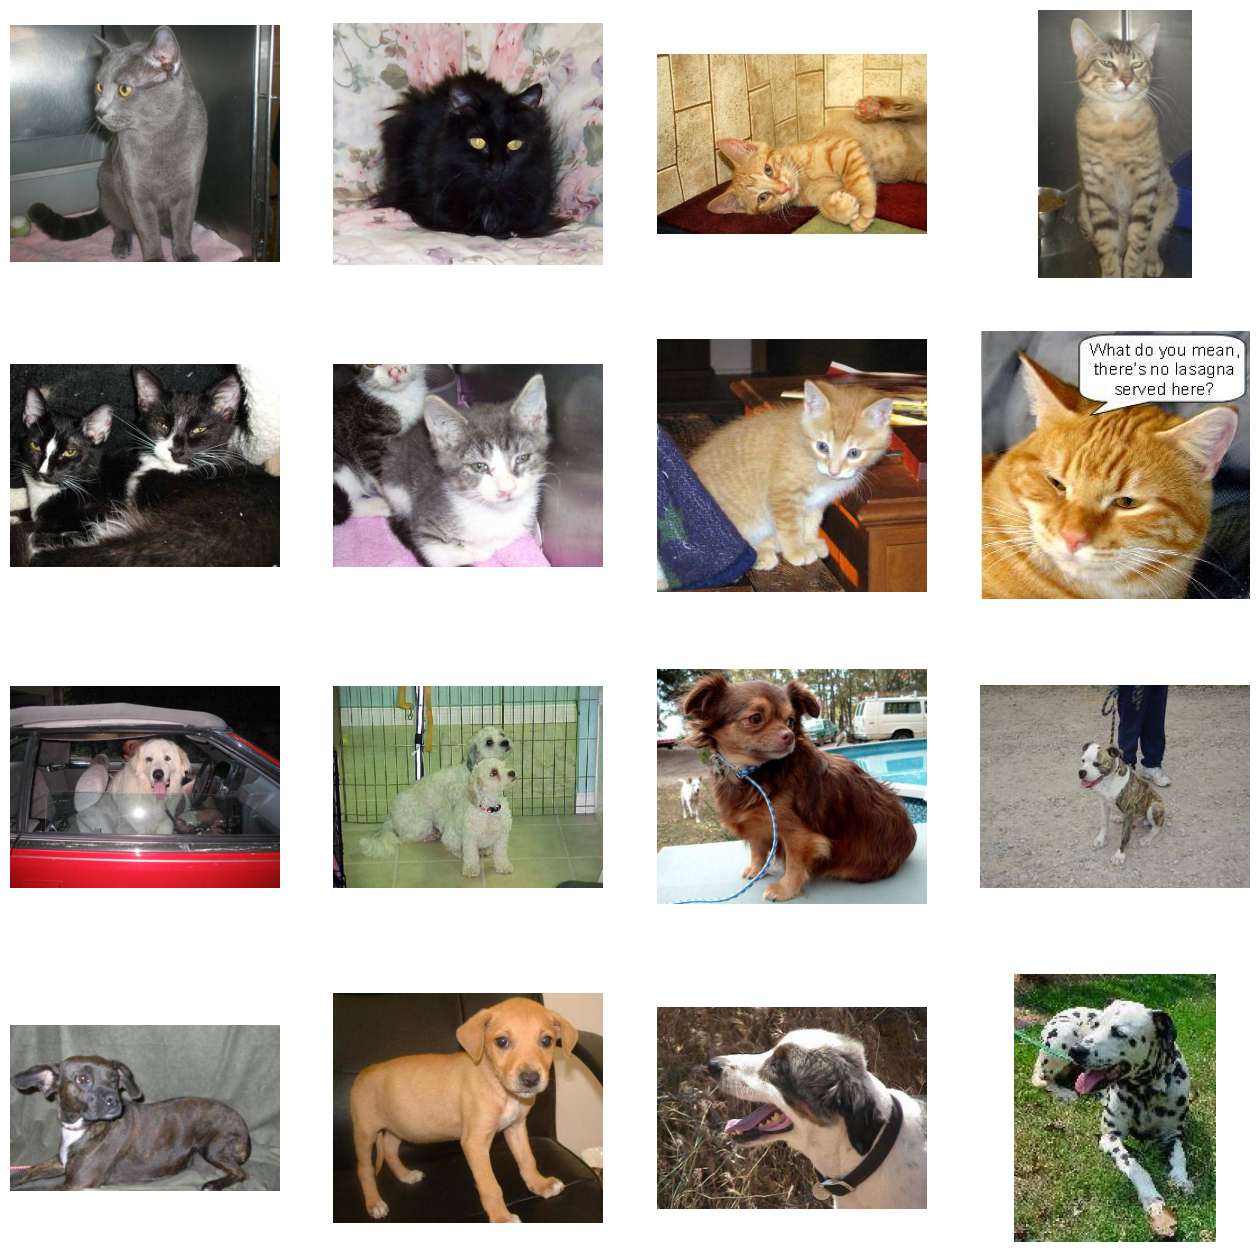

In [4]:
# Set up matplotlib fig, and size it to fit 4x4 pics
fig = plt.gcf()
fig.set_size_inches(nbr_cols * 4, nbr_rows * 4)

next_cat_pix = [os.path.join(TRAIN_IMAGES/"cats", fname)
                for fname in random.sample(train_cat_fnames, k=8)]

next_dog_pix = [os.path.join(TRAIN_IMAGES/"dogs", fname)
                for fname in random.sample(train_dog_fnames, k=8)]

for i, img_path in enumerate(next_cat_pix+next_dog_pix):
    # Set up subplot; subplot indices start at 1
    sp = plt.subplot(nbr_rows, nbr_cols, i + 1)
    sp.axis('Off')

    img = mpimg.imread(img_path)
    plt.imshow(img)

plt.show()

In [5]:
BATCH = 32
SEED = 42

In [6]:
common = dict(
    image_size=(200, 200),
    batch_size=BATCH,
    label_mode="binary",
)

train_data = keras.utils.image_dataset_from_directory(
    directory=TRAIN_IMAGES,
    validation_split=0.3,
    subset="training",
    shuffle=True,
    seed=SEED,
    **common,
)

val_data = keras.utils.image_dataset_from_directory(
    directory=TRAIN_IMAGES,
    validation_split=0.3,
    subset="validation",
    shuffle=True,
    seed=SEED,
    **common,
)

Found 25000 files belonging to 2 classes.
Using 17500 files for training.
Found 25000 files belonging to 2 classes.


E0000 00:00:1792575571.750501   16189 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1792575571.750879   16500 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
W0000 00:00:1792575571.767429   16189 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Using 7500 files for validation.


In [7]:
test_data = keras.utils.image_dataset_from_directory(
    directory=TEST_IMAGES,
    labels=None,
    shuffle=False,
    **common,
)

Found 12500 files.


## Preprocess

In [8]:
SHUFFLE_BUFFER_SIZE = 1000
PREFETCH_BUFFER = tf.data.AUTOTUNE

train_data_final = train_data.shuffle(SHUFFLE_BUFFER_SIZE).prefetch(PREFETCH_BUFFER)
validation_data_final = val_data.prefetch(PREFETCH_BUFFER)

## Build model

In [9]:
model = tf.keras.Sequential([
    tf.keras.Input(shape=(200, 200, 3)),
    tf.keras.layers.Rescaling(1./255),
    tf.keras.layers.Conv2D(16, (3,3), activation="relu", use_bias=True),
    tf.keras.layers.MaxPool2D(2,2),
    tf.keras.layers.Conv2D(32, (3,3), activation="relu", use_bias=True),
    tf.keras.layers.MaxPool2D(2,2),
    tf.keras.layers.Conv2D(32, (3,3), activation="relu", use_bias=True),
    tf.keras.layers.MaxPool2D(2,2),
    tf.keras.layers.Conv2D(64, (3,3), activation="relu", use_bias=True),
    tf.keras.layers.MaxPool2D(2,2),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation="relu", use_bias=True),
    tf.keras.layers.Dense(64, activation="relu", use_bias=True),
    tf.keras.layers.Dense(64, activation="relu", use_bias=True),
    tf.keras.layers.Dense(1, activation="sigmoid", use_bias=True)
    ])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 200, 200, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 198, 198, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 99, 99, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 97, 97, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 46, 46, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 23, 23, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 21, 21, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 10, 10, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       409,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 450,881 (1.72 MB)

 Trainable params: 450,881 (1.72 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
model.compile(
    optimizer = tf.keras.optimizers.RMSprop(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.AUC(name="auc"),
        keras.metrics.Precision(name="Precision", thresholds=0.5),
        keras.metrics.Recall(name="Recall", thresholds=0.5),
        keras.metrics.F1Score(name="F1-score", threshold=0.5)
        ]
)

In [11]:
history = model.fit(
    train_data_final,
    validation_data=validation_data_final,
    epochs=10,
    verbose=1
)

Epoch 1/10


/home/bode-murairi/anaconda3/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


547/547 ━━━━━━━━━━━━━━━━━━━━ 135s 239ms/step - F1-score: 0.5972 - Precision: 0.5697 - Recall: 0.6274 - accuracy: 0.5785 - auc: 0.6191 - loss: 0.6682 - val_F1-score: 0.6629 - val_Precision: 0.6530 - val_Recall: 0.6730 - val_accuracy: 0.6544 - val_auc: 0.7217 - val_loss: 0.6292
Epoch 2/10
547/547 ━━━━━━━━━━━━━━━━━━━━ 154s 264ms/step - F1-score: 0.6641 - Precision: 0.6832 - Recall: 0.6461 - accuracy: 0.6746 - auc: 0.7369 - loss: 0.6017 - val_F1-score: 0.6860 - val_Precision: 0.7703 - val_Recall: 0.6183 - val_accuracy: 0.7143 - val_auc: 0.7937 - val_loss: 0.5620
Epoch 3/10
547/547 ━━━━━━━━━━━━━━━━━━━━ 123s 220ms/step - F1-score: 0.7094 - Precision: 0.7238 - Recall: 0.6955 - accuracy: 0.7162 - auc: 0.7904 - loss: 0.5520 - val_F1-score: 0.7575 - val_Precision: 0.7184 - val_Recall: 0.8011 - val_accuracy: 0.7411 - val_auc: 0.8193 - val_loss: 0.5285
Epoch 4/10
547/547 ━━━━━━━━━━━━━━━━━━━━ 128s 230ms/step - F1-score: 0.7294 - Precision: 0.7432 - Recall: 0.7162 - accuracy: 0.7354 - auc: 0.8174 - 